# Fraud Detection: EDA Analysis

**Goal:** Look at the cleaned data and find out what fraud clients look like.

How to read this notebook:
- Every code cell has a short **explanation before it** (what we do and why).
- After the output there is an **Insight** (what we learned, in plain words).

We use the cleaned files in `data/clean/` (made by `cleaning.py`). Only the **train** tables have the fraud label (`target`), so all tests use train.

## 1. Import libraries and load the data

We use `pandas` for tables and `matplotlib` for plots.

In [1]:
# pandas for tables, matplotlib for plots
import pandas as pd
import matplotlib.pyplot as plt

# show up to 30 columns, so wide tables are not cut off
pd.set_option("display.max_columns", 30)

Now we load the four cleaned tables. The date columns are read as real dates, so we can sort by time later.

In [2]:
# the cleaned files made by cleaning.py
CLEAN_DIR = "data/clean"

# load the four tables and read the date columns as real dates, so we can sort by time later
client_train = pd.read_csv(f"{CLEAN_DIR}/client_train_clean.csv", parse_dates=["creation_date"])
invoice_train = pd.read_csv(f"{CLEAN_DIR}/invoice_train_clean.csv", parse_dates=["invoice_date"], low_memory=False)
client_test = pd.read_csv(f"{CLEAN_DIR}/client_test_clean.csv", parse_dates=["creation_date"])
invoice_test = pd.read_csv(f"{CLEAN_DIR}/invoice_test_clean.csv", parse_dates=["invoice_date"], low_memory=False)

**Insight:** All four files load without errors.

## 2. How big are the tables?

We print the number of rows and columns of each table.

In [3]:
# rows and columns of each table: clients have one row each, invoices have many rows per client
print("client_train: ", client_train.shape)
print("invoice_train:", invoice_train.shape)
print("client_test:  ", client_test.shape)
print("invoice_test: ", invoice_test.shape)

client_train:  (135493, 6)
invoice_train: (4476749, 16)
client_test:   (58069, 5)
invoice_test:  (1939730, 16)


**Insight:**
- The **client** tables have **one row per client** (135,493 in train, 58,069 in test).
- The **invoice** tables have **many rows per client** (about 4.5 million in train, 1.9 million in test).
- Test has one column less than train, because it has no `target`.

The model needs one row per client. So later we must turn the many invoices of a client into a few numbers (this is feature engineering).

## 3. First look at the client table

Each row is one client. `target` = 1 means fraud, 0 means no fraud.

In [4]:
# first rows of the client table: one row per client, target = 1 means fraud
client_train.head()

,district,client_id,client_catg,region,creation_date,target
0,60,train_Client_0,11,101,1994-12-31,0.0
1,69,train_Client_1,11,107,2002-05-29,0.0
2,62,train_Client_10,11,301,1986-03-13,0.0
3,69,train_Client_100,11,105,1996-07-11,0.0
4,62,train_Client_1000,11,303,2014-10-14,0.0


**Insight:**
- `district`, `client_catg` and `region` look like numbers, but they are **codes for groups**. We should not do maths with them (for example an average region makes no sense).
- `creation_date` is when the client joined. We could use it to calculate how long someone has been a client.
- `target` is what we want to predict.

## 4. First look at the invoice table

Each row is one bill (invoice) of one client.

In [5]:
# first rows of the invoice table: one row per bill
invoice_train.head()

,client_id,invoice_date,tarif_type,counter_number,counter_statue,counter_code,reading_remarque,counter_coefficient,consommation_level_1,consommation_level_2,consommation_level_3,consommation_level_4,old_index,new_index,months_number,counter_type
0,train_Client_0,2014-03-24,11,1335667,0.0,203,8,1,82,0,0,0,14302,14384,4,ELEC
1,train_Client_0,2013-03-29,11,1335667,0.0,203,6,1,1200,184,0,0,12294,13678,4,ELEC
2,train_Client_0,2015-03-23,11,1335667,0.0,203,8,1,123,0,0,0,14624,14747,4,ELEC
3,train_Client_0,2015-07-13,11,1335667,0.0,207,8,1,102,0,0,0,14747,14849,4,ELEC
4,train_Client_0,2016-11-17,11,1335667,0.0,207,9,1,572,0,0,0,15066,15638,12,ELEC


**Insight:**
- The same `client_id` appears in many rows: one row per bill, in different years.
- The four `consommation_level` columns show how much was used on that bill. `old_index` and `new_index` are the meter readings before and after.
- `counter_type` is the meter type: ELEC (electricity) or GAZ (gas).

## 5. How many bills does one client have?

Each row in the invoice table is **one bill**. So the number of bills of a client is the same as the number of rows with that `client_id`. We count the rows per client and look at the summary (smallest, typical, largest).

In [6]:
# one row is one bill, so counting rows per client gives the number of bills
invoices_per_client = invoice_train.groupby("client_id").size()
# summary: smallest, typical (median) and largest number of bills
invoices_per_client.describe()

count    135493.000000
mean         33.040445
std          26.092229
min           1.000000
25%          10.000000
50%          30.000000
75%          50.000000
max         439.000000
dtype: float64

**Insight:**
- A **typical** client (median) has **30 bills**. Half of the clients have fewer, half have more.
- The smallest client has **1 bill**, the largest has **439 bills**.
- Most clients (the middle 50%) have between 10 and 50 bills.

## 6. Do the tables fit together?

Every bill should belong to a client in the client table, and every client should have bills. We check this.

In [9]:
# share of bills whose client_id is in the client table (1.0 = all of them)
print("train: bills with a known client:", invoice_train["client_id"].isin(client_train["client_id"]).mean())
print("test:  bills with a known client:", invoice_test["client_id"].isin(client_test["client_id"]).mean())
# number of clients that have no bill at all
print("train: clients without bills:", (~client_train["client_id"].isin(invoice_train["client_id"])).sum())
print("test:  clients without bills:", (~client_test["client_id"].isin(invoice_test["client_id"])).sum())

train: bills with a known client: 1.0
test:  bills with a known client: 1.0
train: clients without bills: 0
test:  clients without bills: 0


**Insight:**
- All bills (1.0 = 100%) belong to a known client, and every client has at least one bill.
- So joining the tables on `client_id` loses nobody and creates no gaps.

## 7. How many clients are fraud?

This is the share of fraud (1) and no fraud (0) in the train data.

{0.0: 127927, 1.0: 7566}
{0.0: 0.9442, 1.0: 0.0558}


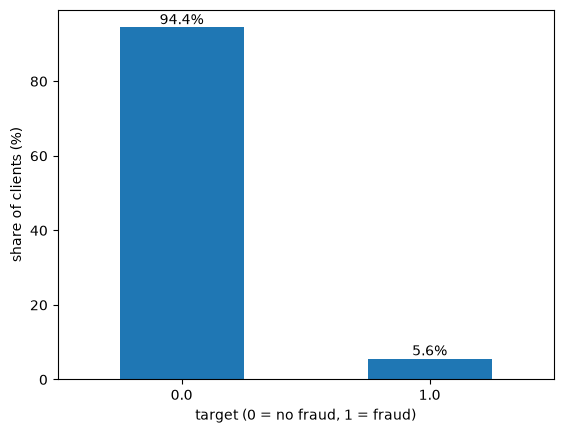

In [10]:
# number and share of fraud (1) and no fraud (0) clients
counts = client_train["target"].value_counts()
share = client_train["target"].value_counts(normalize=True).round(4)
print(counts.to_dict())
print(share.to_dict())

# bar chart of the shares in %, with the value written on each bar
ax = (share * 100).plot(kind="bar", rot=0)
ax.bar_label(ax.containers[0], fmt="%.1f%%")
plt.xlabel("target (0 = no fraud, 1 = fraud)")
plt.ylabel("share of clients (%)")
plt.show()

**Insight:**
- Only **5.6%** of the clients are fraud (7,566 of 135,493). Fraud is rare: the data is **imbalanced**.
- Accuracy would be misleading. A model that says "no fraud" for everyone is right 94% of the time, but finds no fraud at all.
- That is why we judge the model with the **F1 score**, precision and recall.
- **5.6% is our reference.** In the next steps we compare each group (for example each region) with this number.

# Hypothesis tests

We test 9 hypotheses. **The numbers and the order are the same as in [hypotheses.md](hypotheses.md)**, so you can look them up there.

| # | Hypothesis |
|---|---|
| 1 | The fraud rate differs by region |
| 2 | A sudden change in consumption indicates fraud |
| 3 | An index mismatch indicates fraud |
| 4 | The fraud rate differs by tariff type |
| 5 | `reading_remarque` has an impact on fraud |
| 6 | A negative index difference indicates fraud |
| 7 | Outliers show fraud |
| 8 | The fraud rate differs by client category (`client_catg`) |
| 9 | The meter setup (electricity, gas or both) has an impact on fraud |

For each hypothesis we ask: **does the fraud rate change between groups?** We compare each group with the overall fraud rate of **5.6%** (red line in the charts). A big difference means the column is useful for the model. No difference means it is not.

**Review by our data analyst agent:** the agent checked this notebook and found that many effects depend on the **number of bills** of a client. Changes made because of its suggestions are marked in the text with "after the review of our data analyst agent".

## First check: does the number of bills matter?

*Added after the review of our data analyst agent.*

A client with many bills has more chances to show an odd value (a big jump, a mismatch, a big bill) just by luck. So before we test the hypotheses we check if the number of bills is linked to fraud itself.

We count the bills of each client and put the clients in four groups of similar size.

In [11]:
# count the bills of each client and add them to the client table with its target
bills = client_train[["client_id", "target"]].merge(
    invoice_train.groupby("client_id").size().rename("n_bills").reset_index(), on="client_id")
# put the clients in four groups by number of bills, so we can compare similar clients later
bills["bill_group"] = pd.cut(bills["n_bills"], [0, 10, 30, 50, 1000],
                             labels=["1 to 10", "11 to 30", "31 to 50", "51 or more"])

# fraud rate (mean of target) and number of clients in each bill group
bill_result = bills.groupby("bill_group", observed=True)["target"].agg(["mean", "count"])
bill_result["fraud_%"] = (bill_result["mean"] * 100).round(1)
bill_result.rename(columns={"count": "clients"})[["clients", "fraud_%"]]

,clients,fraud_%
bill_group,,
1 to 10,33931,1.3
11 to 30,35508,4.8
31 to 50,32732,7.5
51 or more,33322,9.0


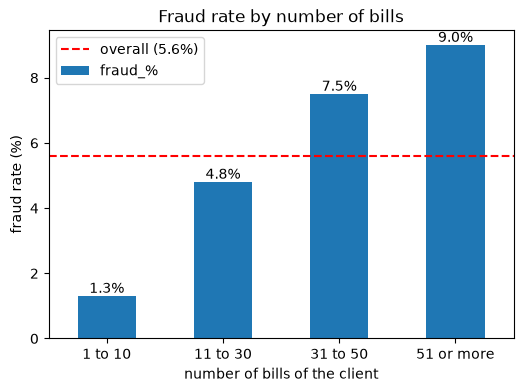

In [12]:
# bar chart of the fraud rate per bill group
ax = bill_result["fraud_%"].plot(kind="bar", rot=0, figsize=(6, 4))
ax.bar_label(ax.containers[0], fmt="%.1f%%")
# red line = overall fraud rate, our reference
plt.axhline(client_train["target"].mean() * 100, color="red", linestyle="--", label="overall (5.6%)")
plt.xlabel("number of bills of the client")
plt.ylabel("fraud rate (%)")
plt.title("Fraud rate by number of bills")
plt.legend()
plt.show()

**Insight:**
- The fraud rate **goes up with the number of bills**: 1.3% (1 to 10 bills), 4.8%, 7.5% and **9.0%** (51 or more).
- Fraud clients have a median of **41 bills**, no-fraud clients **29**.
- So the number of bills is a strong factor by itself. For hypotheses 2, 3, 8 and 9 we also check the effect **inside each bill group**, so we compare clients with a similar number of bills.

**Next step:** Use `n_bills` as a feature.

## Hypothesis 1: the fraud rate differs by region

The `region` column is a code for the area of the client.

**Idea:** some regions have more fraud than others.

We calculate the fraud rate for every region. We also show how many clients each region has, because a rate from only a few clients is not reliable.

In [13]:
# fraud rate and number of clients per region, highest fraud rate first
region_result = client_train.groupby("region")["target"].agg(["mean", "count"])
region_result["fraud_%"] = (region_result["mean"] * 100).round(1)
region_result = region_result.rename(columns={"count": "clients"}).sort_values("fraud_%", ascending=False)
region_result[["clients", "fraud_%"]]

,clients,fraud_%
region,,
103,8964,10.3
372,644,10.1
311,12406,8.0
106,706,7.5
308,841,7.3
371,2065,7.2
313,2076,7.1
379,583,6.7
304,3828,6.7


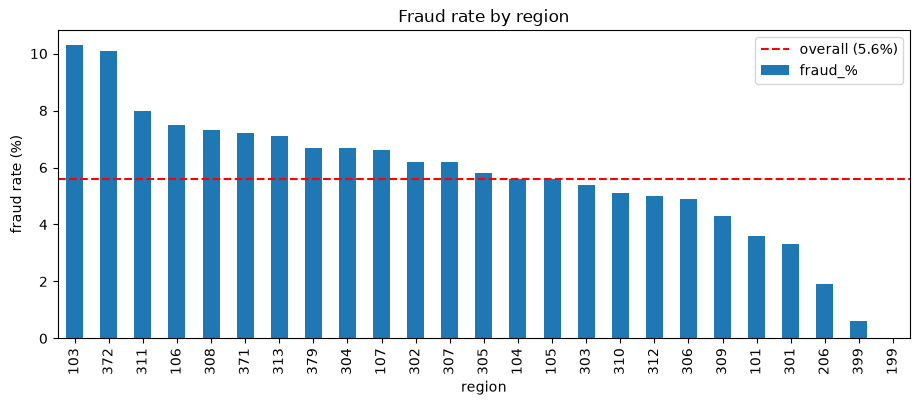

In [14]:
# bar chart of the fraud rate per region
ax = region_result["fraud_%"].plot(kind="bar", figsize=(11, 4))
# red line = overall fraud rate, our reference
plt.axhline(client_train["target"].mean() * 100, color="red", linestyle="--", label="overall (5.6%)")
plt.xlabel("region")
plt.ylabel("fraud rate (%)")
plt.title("Fraud rate by region")
plt.legend()
plt.show()

**Insight:**
- **Region 103** (8,964 clients) has **10.3%** fraud, almost twice the average. **Region 311** (12,406 clients) has 8.0%. Both have many clients, so these rates are reliable.
- **Region 101** (33,770 clients, the biggest) has only **3.6%**, and region 301 (9,544 clients) has 3.3%. Also reliable.
- Regions 372 (10.1%), 399 (0.6%), 206 (1.9%) and 199 (0%) look extreme, but they have only 2 to 644 clients. We should not trust them.

**Result:** Supported. Region clearly matters.
**Next step:** Keep `region` as a category feature.

## Hypothesis 2: a sudden change in consumption indicates fraud

*Changed after the review of our data analyst agent: the jumps are now calculated within each meter, not across meters).*

**Idea:** fraud clients do not use electricity or gas steadily. Their consumption jumps up and down.

Each bill has a total consumption (the four levels added up). For each client we sort the bills by date **within each meter** (a client can have an electricity and a gas meter, and we must not compare a gas bill with an electricity bill) and calculate:
- `max_change`: the **biggest jump** between two bills after each other (up or down).
- `std_cons`: the **standard deviation** of all bills. It shows how much the consumption varies. A steady client has a small value.

Then we compare the **median** of fraud clients with the median of no-fraud clients.

In [15]:
# total consumption of each bill = the four levels added up
consumption_cols = [f"consommation_level_{i}" for i in range(1, 5)]
invoice_train["consumption"] = invoice_train[consumption_cols].sum(axis=1)

# sort the bills by date within each meter, so we never compare a gas bill with an electricity bill
meter = ["client_id", "counter_type", "counter_number"]
invoice_train = invoice_train.sort_values(meter + ["invoice_date"])
# size of the jump between two bills after each other on the same meter (up or down)
invoice_train["change"] = invoice_train.groupby(meter)["consumption"].diff().abs()

# per client: the biggest jump and the standard deviation of all bills
change_per_client = invoice_train.groupby("client_id").agg(
    max_change=("change", "max"),
    std_cons=("consumption", "std"),
).reset_index()
# left join keeps every client, also those without a jump
change = client_train.merge(change_per_client, on="client_id", how="left")

# compare the median of fraud and no-fraud clients
change_result = change.groupby("target")[["max_change", "std_cons"]].median().round(0)
change_result.index = ["no fraud (0)", "fraud (1)"]
change_result

,max_change,std_cons
no fraud (0),930.0,320.0
fraud (1),1530.0,453.0


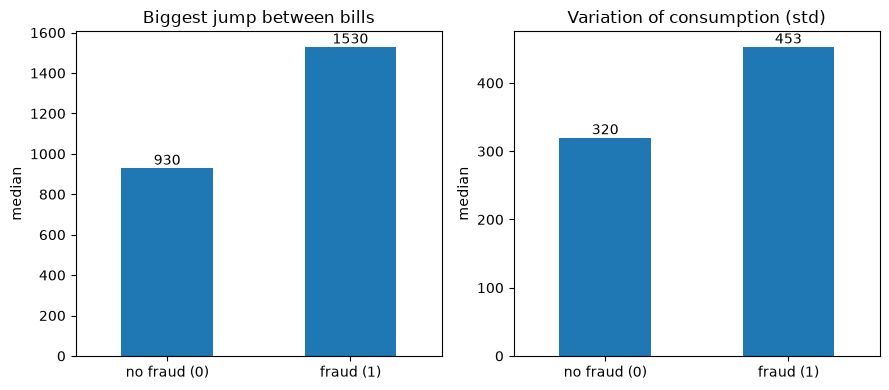

In [16]:
# one bar chart for each measure: biggest jump and std, fraud vs no fraud
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
for ax, col, title in zip(axes, ["max_change", "std_cons"], ["Biggest jump between bills", "Variation of consumption (std)"]):
    ax = change_result[col].plot(kind="bar", rot=0, ax=ax)
    ax.bar_label(ax.containers[0], fmt="%d")
    ax.set_title(title)
    ax.set_ylabel("median")
plt.tight_layout()
plt.show()

**Insight:**
- The biggest jump between two bills is **1,530** for fraud clients and **930** for no-fraud clients (about **65% higher**).
- The variation (std) is **453** vs **320** (about **40% higher**).
- Fraud clients have less steady consumption.
- Clients with only 1 bill on a meter have no jump (missing value). This is more common for no-fraud clients.

The agent warned that clients with more bills have bigger jumps just by chance. Do we still see the difference when the number of bills is similar?

In [17]:
# add the bill group to each client, so we compare clients with a similar number of bills
change_groups = change.merge(bills[["client_id", "bill_group"]], on="client_id")
# median biggest jump per bill group, fraud vs no fraud side by side
group_change = change_groups.groupby(["bill_group", "target"], observed=True)["max_change"].median().unstack().round(0)
group_change.columns = ["no fraud (0)", "fraud (1)"]
group_change

,no fraud (0),fraud (1)
bill_group,,
1 to 10,375.0,1432.0
11 to 30,972.0,1785.0
31 to 50,1092.0,1534.0
51 or more,1154.0,1395.0


**Insight:**
- In **every** bill group fraud clients have the bigger jump: 1,432 vs 375 (1 to 10 bills), 1,785 vs 972, 1,534 vs 1,092 and 1,395 vs 1,154 (51 or more).
- The gap gets smaller with more bills. So part of the first result came from the number of bills, but the difference stays.

**Result:** Supported, also with the same number of bills.
**Next step:** Create `max_change` and `std_cons` as features.

## Hypothesis 3: an index mismatch indicates fraud

*Changed after the review of our data analyst agent: we check the effect inside each bill group, and we note that hypotheses 3 and 6 overlap).*

For every bill the consumption should be the difference of the two meter readings: `new_index - old_index`. It should be the same as the four consumption levels added up.

**Idea:** if the two numbers are different, something is wrong, and that could be fraud.

For each client we count the bills where the two numbers differ, and compare the fraud rate of clients with and without a mismatch.

In [18]:
# flag bills where new_index - old_index is not the same as the total consumption
invoice_train["mismatch"] = ((invoice_train["new_index"] - invoice_train["old_index"]) != invoice_train["consumption"]).astype(int)

# count the mismatching bills of each client
mismatch_per_client = invoice_train.groupby("client_id")["mismatch"].sum().rename("mismatch_count").reset_index()
mismatch = client_train.merge(mismatch_per_client, on="client_id", how="left")
# True if the client has at least one mismatch
mismatch["has_mismatch"] = mismatch["mismatch_count"] > 0

# fraud rate and number of clients with and without a mismatch
mismatch_result = mismatch.groupby("has_mismatch")["target"].agg(["mean", "count"])
mismatch_result["fraud_%"] = (mismatch_result["mean"] * 100).round(1)
mismatch_result.index = ["no mismatch", "has mismatch"]
mismatch_result.rename(columns={"count": "clients"})[["clients", "fraud_%"]]

,clients,fraud_%
no mismatch,127528,5.4
has mismatch,7965,8.5


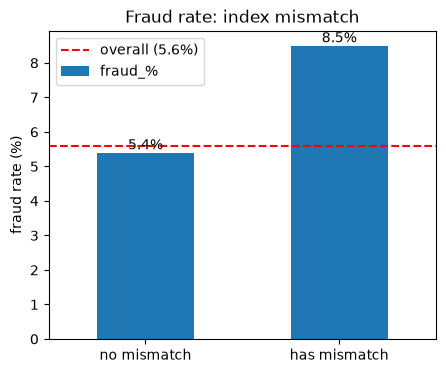

In [19]:
# bar chart of the fraud rate with and without a mismatch
ax = mismatch_result["fraud_%"].plot(kind="bar", rot=0, figsize=(5, 4))
ax.bar_label(ax.containers[0], fmt="%.1f%%")
# red line = overall fraud rate, our reference
plt.axhline(client_train["target"].mean() * 100, color="red", linestyle="--", label="overall (5.6%)")
plt.ylabel("fraud rate (%)")
plt.title("Fraud rate: index mismatch")
plt.legend()
plt.show()

**Insight:**
- Clients **without** a mismatch: 5.4% fraud (127,528 clients).
- Clients **with** at least one mismatch: **8.5%** fraud (7,965 clients), about **1.6 times** more.
- Only about 6% of the clients have a mismatch, so it is a rare flag.
- Careful: every backward bill (hypothesis 6) is also counted as a mismatch, so hypotheses 3 and 6 partly measure the same thing.

Clients with a mismatch have more bills (median 52 vs 28). Do we still see the difference with a similar number of bills?

In [20]:
# add the bill group, so we compare clients with a similar number of bills
mismatch_groups = mismatch.merge(bills[["client_id", "bill_group"]], on="client_id")
# fraud rate in % per bill group, with and without a mismatch
group_mismatch = mismatch_groups.groupby(["bill_group", "has_mismatch"], observed=True)["target"].mean().unstack() * 100
group_mismatch.columns = ["no mismatch", "has mismatch"]
group_mismatch.round(1)

,no mismatch,has mismatch
bill_group,,
1 to 10,1.3,3.7
11 to 30,4.7,5.6
31 to 50,7.4,8.9
51 or more,8.9,9.6


**Insight:**
- Inside each bill group the mismatch clients still have the higher fraud rate, but the gap is **small**: 1.3% vs 3.7% (1 to 10 bills), 4.7% vs 5.6%, 7.4% vs 8.9% and 8.9% vs 9.6% (51 or more).
- So most of the first difference (5.4% vs 8.5%) came from the number of bills.

**Result:** Weak. A small effect remains after we compare clients with a similar number of bills.
**Next step:** Create `has_mismatch` and `mismatch_count`, but also use the share of mismatching bills, and expect a small gain only.

## Hypothesis 4: the fraud rate differs by tariff type

`tarif_type` is the price plan of the client. A client can have bills with different plans, so for each client we take the **most common** plan.

**Idea:** some plans have more fraud than others.

In [21]:
# a client can have bills with different plans, so we take the most common plan (mode)
tariff_per_client = invoice_train.groupby("client_id")["tarif_type"].agg(lambda s: s.mode().iloc[0]).reset_index()
tariff = client_train.merge(tariff_per_client, on="client_id", how="left")

# fraud rate and number of clients per plan, biggest plans first
tariff_result = tariff.groupby("tarif_type")["target"].agg(["mean", "count"])
tariff_result["fraud_%"] = (tariff_result["mean"] * 100).round(1)
tariff_result = tariff_result.rename(columns={"count": "clients"}).sort_values("clients", ascending=False)
tariff_result[["clients", "fraud_%"]]

,clients,fraud_%
tarif_type,,
11,114072,5.2
10,11387,6.8
40,9018,7.7
12,316,9.5
15,206,12.6
13,181,6.6
45,159,12.6
29,58,17.2
9,56,3.6


Small plans have very few clients, so their rates are not reliable. In the chart we only show the three big plans (more than 5,000 clients each).

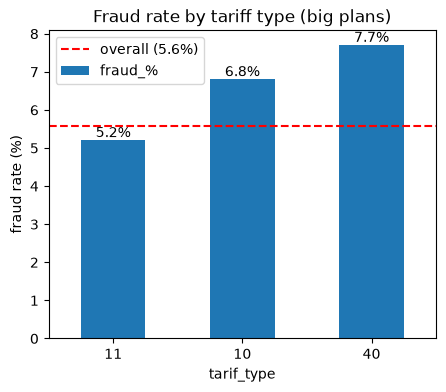

In [22]:
# only the big plans (more than 5,000 clients), because rates from small plans are not reliable
big_tariffs = tariff_result[tariff_result["clients"] > 5000]
ax = big_tariffs["fraud_%"].plot(kind="bar", rot=0, figsize=(5, 4))
ax.bar_label(ax.containers[0], fmt="%.1f%%")
# red line = overall fraud rate, our reference
plt.axhline(client_train["target"].mean() * 100, color="red", linestyle="--", label="overall (5.6%)")
plt.xlabel("tarif_type")
plt.ylabel("fraud rate (%)")
plt.title("Fraud rate by tariff type (big plans)")
plt.legend()
plt.show()

**Insight:**
- Three plans cover almost all clients: **11** (114,072 clients, 5.2%), **10** (11,387 clients, 6.8%) and **40** (9,018 clients, 7.7%).
- Plan **40** has about 1.4 times the average fraud rate, and it has enough clients to trust.
- Small plans such as 29 (17.2%, 58 clients) or 14 (13.8%, 29 clients) look high, but we cannot trust them with so few clients.

**Result:** Supported for the large plans.
**Next step:** Keep `tarif_type` as a category feature. Group the rare plans into "other".

## Hypothesis 5: `reading_remarque` has an impact on fraud

`reading_remarque` is a note from the person who reads the meter. In the cleaning step the rare codes were grouped into 0 ("other"), so the codes are 0, 6, 7, 8 and 9.

**Idea:** if one remark mostly appears for fraud clients, it is a clue.

A client can get different remarks on different bills. So for each remark we look at all clients who got that remark **at least once** and calculate how many of them are fraud.

In [23]:
# one row per client and remark, so each client counts once for every remark it got at least once
remark_clients = invoice_train[["client_id", "reading_remarque"]].drop_duplicates()
# add the fraud label of each client
remark_clients = remark_clients.merge(client_train[["client_id", "target"]], on="client_id")

# fraud rate and number of clients per remark
remark_result = remark_clients.groupby("reading_remarque")["target"].agg(["mean", "count"])
remark_result["fraud_%"] = (remark_result["mean"] * 100).round(1)
remark_result.rename(columns={"count": "clients"})[["clients", "fraud_%"]]

,clients,fraud_%
reading_remarque,,
0,5,0.0
6,119781,6.0
7,478,0.2
8,95591,7.2
9,116596,6.4


The table is easier to read as a chart. Each bar is the fraud rate of one remark. The red line is the overall fraud rate (5.6%).

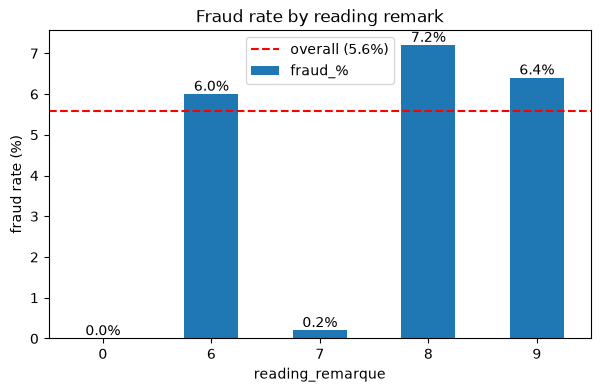

In [24]:
# bar chart of the fraud rate per remark
plot_data = remark_result["fraud_%"]
ax = plot_data.plot(kind="bar", rot=0, figsize=(7, 4))
ax.bar_label(ax.containers[0], fmt="%.1f%%")
# red line = overall fraud rate, our reference
plt.axhline(client_train["target"].mean() * 100, color="red", linestyle="--", label="overall (5.6%)")
plt.xlabel("reading_remarque")
plt.ylabel("fraud rate (%)")
plt.title("Fraud rate by reading remark")
plt.legend()
plt.show()

**Insight:**
- Remarks **6, 8 and 9** cover almost all clients (about 96,000 to 120,000 each). Their fraud rates are close to the overall 5.6%: 6.0%, 7.2% and 6.4%. Remark 8 is a little higher.
- Remark **7** is very different: only **0.2%** fraud (478 clients). Clients with this remark are almost never fraud.
- Remark 0 has only 5 clients, so we cannot trust its 0%.

**Result:** Partly supported. The remark has a small effect. The clear signal is remark 7, which points to *no* fraud.
**Next step:** Keep `reading_remarque` as a category feature.

## Hypothesis 6: a negative index difference indicates fraud

`new_index - old_index` is the meter reading at the end of a bill minus the reading at the start. It should never be negative, because a meter only counts up. A negative value can mean a meter reset or a rollover (normal), or tampering (fraud).

**Idea:** clients with backward readings are more often fraud.

For each client we count the bills where `new_index` is smaller than `old_index`. Then we compare the fraud rate of clients with and without such bills.

In [25]:
# a meter only counts up, so a negative difference is a backward reading
invoice_train["index_diff"] = invoice_train["new_index"] - invoice_train["old_index"]
invoice_train["backward"] = (invoice_train["index_diff"] < 0).astype(int)

# count the backward bills of each client
backward_per_client = invoice_train.groupby("client_id")["backward"].sum().rename("backward_count").reset_index()
backward = client_train.merge(backward_per_client, on="client_id", how="left")

# fraud rate and number of clients with and without a backward bill
backward["has_backward"] = backward["backward_count"] > 0
backward_result = backward.groupby("has_backward")["target"].agg(["mean", "count"])
backward_result["fraud_%"] = (backward_result["mean"] * 100).round(1)
backward_result.rename(columns={"count": "clients"})[["clients", "fraud_%"]]

,clients,fraud_%
has_backward,,
False,133677,5.5
True,1816,11.3


**Insight:**
- Clients **without** a backward bill: 5.5% fraud (133,677 clients).
- Clients **with** at least one backward bill: **11.3%** fraud (1,816 clients). That is about **twice** the normal rate.
- Only about 1% of the clients have a backward bill, so this is a rare but strong flag.

Does it get stronger with more backward bills?

In [26]:
# group clients by how many backward bills they have, to see if more bills mean more fraud
backward["backward_groups"] = pd.cut(backward["backward_count"], [-1, 0, 1, 3, 1000],
                                      labels=["0", "1", "2-3", "4 or more"])
# fraud rate and number of clients per group
group_result = backward.groupby("backward_groups", observed=True)["target"].agg(["mean", "count"])
group_result["fraud_%"] = (group_result["mean"] * 100).round(1)
group_result.rename(columns={"count": "clients"})[["clients", "fraud_%"]]

,clients,fraud_%
backward_groups,,
0,133677,5.5
1,1519,11.3
2-3,264,11.0
4 or more,33,15.2


**Insight:**
- 0 backward bills: 5.5%, 1 bill: 11.3%, 2 to 3 bills: 11.0%, **4 or more: 15.2%** (only 33 clients).
- The jump comes from the first backward bill. More bills push the rate up a little, but the groups are small.

**Result:** Supported. A negative index difference doubles the fraud rate.
**Next step:** Create the features `has_backward` and `backward_count` for each client. This matches the team decision in `protocol.md`.

## Hypothesis 7: outliers show fraud

The team decided to keep the outliers on purpose (see `protocol.md`). Now we test if they really point to fraud.

**Idea:** clients with extremely high consumption on a bill are more often fraud.

For each bill we add up the four consumption levels. For each client we take the **highest** bill. Then we group the clients by that highest value and compare the fraud rate.

In [27]:
# highest bill (total consumption) of each client
max_cons = invoice_train.groupby("client_id")["consumption"].max().rename("max_consumption").reset_index()
outlier = client_train.merge(max_cons, on="client_id", how="left")

# put the clients in groups by their highest bill
outlier["max_consumption_group"] = pd.cut(
    outlier["max_consumption"],
    [-1, 1000, 5000, 10000, 50000, float("inf")],
    labels=["up to 1,000", "1,000 to 5,000", "5,000 to 10,000", "10,000 to 50,000", "above 50,000"],
)
# fraud rate and number of clients per group
outlier_result = outlier.groupby("max_consumption_group", observed=True)["target"].agg(["mean", "count"])
outlier_result["fraud_%"] = (outlier_result["mean"] * 100).round(1)
outlier_result.rename(columns={"count": "clients"})[["clients", "fraud_%"]]

,clients,fraud_%
max_consumption_group,,
"up to 1,000",50694,2.6
"1,000 to 5,000",73904,6.7
"5,000 to 10,000",6983,11.4
"10,000 to 50,000",3677,13.2
"above 50,000",235,3.8


**Insight:**
- The fraud rate **goes up** as the highest bill gets bigger: 2.6% (up to 1,000), 6.7% (1,000 to 5,000), 11.4% (5,000 to 10,000) and **13.2%** (10,000 to 50,000). That is more than **twice** the overall 5.6%.
- Above 50,000 the rate **drops to 3.8%** (235 clients). Such extreme values are probably typing or meter errors, not real consumption.
- Careful: a client with many bills has a higher chance of one big bill. So part of this effect may come from the number of bills.

**Result:** Supported. High (but not extreme) consumption points to fraud. This is why we keep the outliers and do not cut them.
**Next step:** Use the **max** (and median) of the consumption per client as features. Do not cap the values, but keep in mind that the very largest values may be errors.

## Hypothesis 8: the fraud rate differs by client category

*Added after the review of our data analyst agent.*

`client_catg` is the category of the client (for example private or business). It was not part of our first list.

**Idea:** some categories have more fraud than others.

We calculate the fraud rate for each category, together with the number of clients.

In [28]:
# fraud rate and number of clients per client category
catg_result = client_train.groupby("client_catg")["target"].agg(["mean", "count"])
catg_result["fraud_%"] = (catg_result["mean"] * 100).round(1)
catg_result.rename(columns={"count": "clients"})[["clients", "fraud_%"]]

,clients,fraud_%
client_catg,,
11,131494,5.5
12,2321,4.0
51,1678,16.9


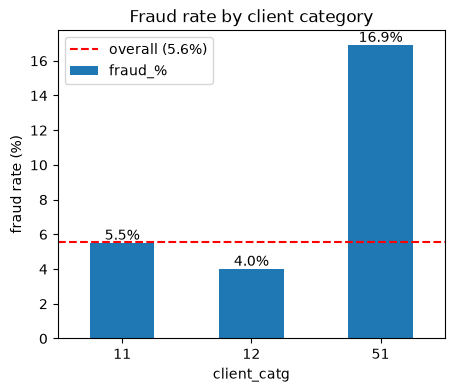

In [29]:
# bar chart of the fraud rate per client category
ax = catg_result["fraud_%"].plot(kind="bar", rot=0, figsize=(5, 4))
ax.bar_label(ax.containers[0], fmt="%.1f%%")
# red line = overall fraud rate, our reference
plt.axhline(client_train["target"].mean() * 100, color="red", linestyle="--", label="overall (5.6%)")
plt.xlabel("client_catg")
plt.ylabel("fraud rate (%)")
plt.title("Fraud rate by client category")
plt.legend()
plt.show()

**Insight:**
- Category **51** (1,678 clients) has **16.9%** fraud, about **3 times** the overall rate.
- Category 11 (131,494 clients, almost everybody) has 5.5% and category 12 (2,321 clients) has 4.0%.

Is this because category 51 clients have more bills? We check inside each bill group:

In [30]:
# add the bill group, so we compare clients with a similar number of bills
catg_groups = client_train.merge(bills[["client_id", "bill_group"]], on="client_id")
# fraud rate in % per bill group and client category
group_catg = catg_groups.groupby(["bill_group", "client_catg"], observed=True)["target"].mean().unstack() * 100
group_catg.round(1)

client_catg,11,12,51
bill_group,,,
1 to 10,1.2,1.2,5.7
11 to 30,4.7,5.0,13.4
31 to 50,7.4,4.9,25.4
51 or more,8.7,5.8,20.7


**Insight:**
- Category 51 is the highest in **every** bill group: 5.7% vs 1.2% (1 to 10 bills), 13.4% vs 4.7%, 25.4% vs 7.4% and 20.7% vs 8.7% (51 or more, compared with category 11).
- So the effect is **not** caused by the number of bills.

**Result:** Supported, a strong signal.
**Next step:** Keep `client_catg` as a category feature.

## Hypothesis 9: the meter setup has an impact on fraud

*Our data analyst agent suggested testing the meter type. We tested it and it is **not supported**. This section shows why we do not use it as a feature.*

A client can have an electricity meter (ELEC), a gas meter (GAZ) or both.

**Idea:** clients with both meters have more chances to manipulate one of them.

For each client we check which meter types appear in the bills.

In [31]:
# per client: "both" if the bills show two meter types, otherwise ELEC or GAZ
setup_per_client = invoice_train.groupby("client_id")["counter_type"].agg(
    lambda s: "both" if s.nunique() > 1 else s.iloc[0]).rename("meter_setup").reset_index()
setup = client_train.merge(setup_per_client, on="client_id", how="left")

# fraud rate and number of clients per meter setup
setup_result = setup.groupby("meter_setup")["target"].agg(["mean", "count"])
setup_result["fraud_%"] = (setup_result["mean"] * 100).round(1)
setup_result.rename(columns={"count": "clients"})[["clients", "fraud_%"]]

,clients,fraud_%
meter_setup,,
ELEC,73439,4.2
GAZ,678,0.9
both,61376,7.2


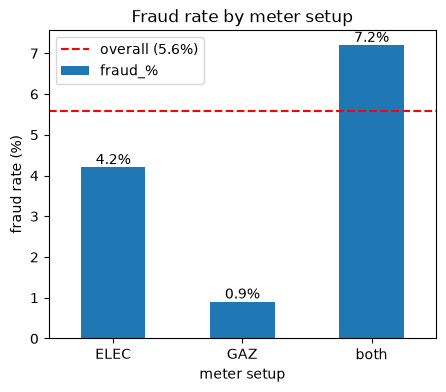

In [32]:
# bar chart of the fraud rate per meter setup
ax = setup_result["fraud_%"].plot(kind="bar", rot=0, figsize=(5, 4))
ax.bar_label(ax.containers[0], fmt="%.1f%%")
# red line = overall fraud rate, our reference
plt.axhline(client_train["target"].mean() * 100, color="red", linestyle="--", label="overall (5.6%)")
plt.xlabel("meter setup")
plt.ylabel("fraud rate (%)")
plt.title("Fraud rate by meter setup")
plt.legend()
plt.show()

**Insight:**
- Clients with **both** meters: **7.2%** fraud (61,376 clients). ELEC only: 4.2% (73,439). GAZ only: 0.9% (678).
- At first sight "both meters" looks risky. But clients with both meters also have many more bills (median 52 vs 16). We check inside each bill group, so we compare clients with a similar number of bills:

In [33]:
# add the bill group, so we compare clients with a similar number of bills
setup_groups = setup.merge(bills[["client_id", "bill_group"]], on="client_id")
# fraud rate in % per bill group and meter setup
group_setup = setup_groups.groupby(["bill_group", "meter_setup"], observed=True)["target"].mean().unstack() * 100
group_setup.round(1)

meter_setup,ELEC,GAZ,both
bill_group,,,
1 to 10,1.2,0.8,1.9
11 to 30,4.9,0.0,4.6
31 to 50,7.6,0.0,7.3
51 or more,12.0,14.3,8.8


**Insight:**
- With a similar number of bills, "both" and "ELEC only" are almost the same: 1.9% vs 1.2% (1 to 10 bills), 4.6% vs 4.9%, 7.3% vs 7.6% and 8.8% vs 12.0% (51 or more).
- So the high rate for "both meters" comes from the number of bills, not from the meter setup. (GAZ only has too few clients in the groups to say anything.)

**Result:** Not supported. The meter setup has no effect of its own.
**Next step:** Do not use it as a feature. The number of bills (`n_bills`) is the useful one.

## Column check: keep or delete the `consommation_level` columns?

This is not one of our hypotheses. It is a check for a decision: **should we keep the four level columns (`consommation_level_1` to `4`) for the model, or is the total consumption enough?**

Each bill splits the consumption into four levels. Most small consumers only use level 1. We wanted to delete the levels, because we thought they only measure the size of the consumption. We keep them only if they tell us something that the total consumption does not.

For each client we calculate the **share of bills that only have level 1** (levels 2, 3 and 4 are 0). Then we put the clients in four groups and compare the fraud rate.

In [34]:
# flag bills that only use level 1 (level 1 above 0, levels 2 to 4 are 0)
levels = [f"consommation_level_{i}" for i in range(1, 5)]
invoice_train["only_level1"] = ((invoice_train["consommation_level_1"] > 0)
                                & (invoice_train[levels[1:]].sum(axis=1) == 0)).astype(int)

# per client: share of level-1-only bills, plus level 1 and total consumption
level1_per_client = invoice_train.groupby("client_id").agg(
    only_level1_share=("only_level1", "mean"),
    level1_sum=("consommation_level_1", "sum"),
    total_sum=("consumption", "sum"),
).reset_index()
# share of the total consumption that is in level 1 (NaN instead of dividing by 0)
level1_per_client["level1_share"] = level1_per_client["level1_sum"] / level1_per_client["total_sum"].replace(0, float("nan"))
level1 = client_train.merge(level1_per_client, on="client_id", how="left")

# put the clients in four groups by their share of level-1-only bills
level1["only_level1_group"] = pd.cut(level1["only_level1_share"], [-0.01, 0, 0.5, 0.999, 1],
                                     labels=["never", "some (up to 50%)", "most (over 50%)", "all bills"])
# fraud rate and number of clients per group
level1_result = level1.groupby("only_level1_group", observed=True)["target"].agg(["mean", "count"])
level1_result["fraud_%"] = (level1_result["mean"] * 100).round(1)
level1_result.rename(columns={"count": "clients"})[["clients", "fraud_%"]]

,clients,fraud_%
only_level1_group,,
never,7639,2.9
some (up to 50%),23518,6.9
most (over 50%),76492,6.9
all bills,27844,1.7


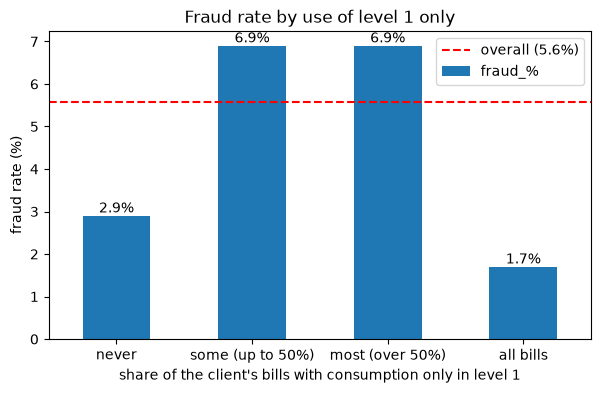

In [35]:
# bar chart of the fraud rate per level 1 group
ax = level1_result["fraud_%"].plot(kind="bar", rot=0, figsize=(7, 4))
ax.bar_label(ax.containers[0], fmt="%.1f%%")
# red line = overall fraud rate, our reference
plt.axhline(client_train["target"].mean() * 100, color="red", linestyle="--", label="overall (5.6%)")
plt.xlabel("share of the client's bills with consumption only in level 1")
plt.ylabel("fraud rate (%)")
plt.title("Fraud rate by use of level 1 only")
plt.legend()
plt.show()

**Insight:**
- Clients whose bills are **all** level 1 are fraud only **1.7%** of the time (27,844 clients), far below the 5.6% average.
- Clients who use higher levels in some or most bills have **6.9%** fraud (about 100,000 clients).
- Clients who **never** have a level-1-only bill have 2.9% (7,639 clients), so the effect is not a straight line.

Level-1-only clients are mostly small consumers. So maybe the levels only show the size. We check clients with a similar **biggest bill**:

In [36]:
# True if all bills of the client are level 1 only
level1["all_level1"] = level1["only_level1_share"] == 1
# add the highest bill and group clients by it, to check if the level effect is only about size
level1 = level1.merge(max_cons, on="client_id", how="left")
level1["max_group"] = pd.cut(level1["max_consumption"], [-1, 1000, 5000, 10000, float("inf")],
                             labels=["up to 1,000", "1,000 to 5,000", "5,000 to 10,000", "above 10,000"])
# fraud rate in % per size group, level-1-only clients vs the others
group_level1 = level1.groupby(["max_group", "all_level1"], observed=True)["target"].mean().unstack() * 100
group_level1.columns = ["uses higher levels", "all bills level 1 only"]
group_level1.round(1)

,uses higher levels,all bills level 1 only
max_group,,
"up to 1,000",3.3,1.4
"1,000 to 5,000",7.2,2.6
"5,000 to 10,000",11.7,0.6
"above 10,000",12.9,1.8


**Insight:**
- In every group the clients with level-1-only bills have the **lower** fraud rate: 3.3% vs 1.4% (up to 1,000), 7.2% vs 2.6%, 11.7% vs 0.6% and 12.9% vs 1.8% (above 10,000).
- So it is **not only a size effect**. Whether a client uses the higher levels tells us something that the total consumption does not.
- Fraud clients also use more of levels 2 and 3. The median of the total level-2 consumption per client is 1,267 for fraud vs 128 for no fraud.

**Decision: keep the level columns.** Deleting them would lose information.
**Next step:** Create `only_level1_share` and `level1_share` for each client, and use them next to the total consumption.